# HMM tie breaking and direct root-to-sample edges

**22 October 2026.** Changing maximum-state selection to prefer the youngest
explicitly represented state reduces direct root copying, without changing
likelihood compression. In the complete 320-individual 1000 Genomes cohort,
root-edge count falls **10,328 → 9,409 (8.90%)** and summed observed root-copying
span falls **6,311,633 → 6,007,794 bp (4.81%)**. Most root edges remain.

Two independent 1 Mb tests already have root edges in their unmodified Full HMM
controls and show reductions. Checks using 64 haplotypes from each of the
1,012- and 3,202-individual references show 9.67% and 12.96% fewer root edges.
All paired real-data paths have identical calculated HMM scores and zero mismatches.

In [1]:
import json
import pathlib
import subprocess

import IPython.display as display
import pandas as pd

from ch5 import nb_plot

repository_dir = pathlib.Path.cwd()

In [2]:
notebook_dir = (
    pathlib.Path(__file__).resolve().parent
    if "__file__" in globals()
    else pathlib.Path.cwd()
)
repository_dir = (
    notebook_dir
    if (notebook_dir / "data/ch5/tie_breaking").is_dir()
    else notebook_dir.parent.parent
)
artifact_dir = repository_dir / "data/ch5/tie_breaking"
settings = json.loads((artifact_dir / "experiment_config.json").read_text())
provenance = json.loads((artifact_dir / "provenance.json").read_text())
summary = pd.read_csv(artifact_dir / "summary.csv")
paired = pd.read_csv(artifact_dir / "paired_haplotypes.csv")
archive = pd.read_csv(artifact_dir / "archive_summary.csv")
toys = pd.read_csv(artifact_dir / "toy_results.csv")

## Context and what counts as the root

The recent “Finish the report” conversation and the executed
[pt9 analysis](stitching_pt9_hpc_perf2.ipynb) established that the Full HMM
baseline itself contains many direct root-to-sample edges. The subsequent
“Plan one-site gap matching fix” conversation identified an additional
single-site-gap problem in stitching. This experiment tests maximum selection
in **Full HMM sample matching**; it does not implement that separate gap fix.
Conversation identifiers and source hashes are saved in `provenance.json`.

Inputs are the saved `data/ch5/hpc_perf2_diagnostics` chr20p references and raw
Full HMM sample trees, generated with recombination 0.01 and mismatch 1e-20.
These cover about 26.05 Mb of observed sequence, not 10 Mb. The archive manifest
records the same tsinfer revision as the local checkout used here.

The archive has a stem edge **node 0 → node 1**. Node 0 is the artificial
ultimate/stem root; node 1 is the ultimate ancestor from which biological
ancestors and samples can copy. The existing root-edge analysis counts
**node 1 → sample** edges, and so do the primary results below. Literal node
0 → sample edges are counted separately: there are none in these archives or
experiments. Root IDs are checked against the reference stem edge rather than
inferred from sample-node numbering.

Edges are squashed across touching equal-parent segments, counted once, and
clipped to the interval between the first and last tested inference sites.
Physical spans are summed over haplotypes; they are not the union of genomic
positions. Artificial chromosome flanks are excluded.

In [3]:
display.display(
    archive[
        [
            "dataset",
            "haplotypes",
            "root_edges",
            "root_span_bp",
            "literal_node0_sample_edges",
        ]
    ]
)

,dataset,haplotypes,root_edges,root_span_bp,literal_node0_sample_edges
0,tgp_chr20p_n320,640,10328,6311633.0,0
1,tgp_chr20p_n1012,2024,14779,7200410.0,0
2,tgp_chr20p_n3202,6404,15208,6533250.0,0


## Intervention: maximum selection only

Three separately compiled C extensions were built from copies of the same
checkout in `/private/tmp/tsinfer_tie_breaking`. No tsinfer checkout file or
installed extension was rebuilt or replaced.

- **Control:** original `if (L[u] > max_L)`; the first maximum wins.
- **Youngest explicit:** on exact likelihood equality, select the node with
  smaller `nodes.time`. Equal-time ties keep their original order.
- **Last stored (`>=`):** replace `>` with `>=`; this chooses the last stored
  maximum and is a separate diagnostic, not a reliable age comparison.

The age-aware comparator is:

```c
if (L[u] > max_L
    || (L[u] == max_L
        && self->matcher_indexes->node_time[u]
            < self->matcher_indexes->node_time[max_L_node])) {
    max_L = L[u];
    max_L_node = u;
}
```

Since the original indexes do not retain ages, the experimental build also
copies `tables->nodes.time` into a shared `node_time` array and frees it with
the indexes. This is the only supporting plumbing. It uses actual ages, not
node IDs. The full source diff is shown below.

**Likelihood compression, state initialisation, emissions, transitions,
numerical thresholds and traceback logic are unchanged.** The coalescing
function was checked byte-for-byte against the original in every build.
Consequently, this intervention cannot choose a younger state that is
represented implicitly by an older state.

In [4]:
display.display(
    display.Markdown(
        "```diff\n" + (artifact_dir / "youngest.diff").read_text() + "\n```"
    )
)
display.display(display.Markdown(f"tsinfer revision: `{provenance['tsinfer_commit']}`"))
assert provenance["source_control_matches_checkout"]
assert provenance["compressed_likelihood_function_unchanged"]
assert provenance["original_tracked_diff"] == ""

```diff
--- a/lib/tsinfer.h
+++ b/lib/tsinfer.h
@@ -176,6 +176,7 @@
         mutation_list_node_t **mutations;
         tsk_size_t *num_alleles;
     } sites;
+    double *node_time;
     edge_t *left_index_edges;
     edge_t *right_index_edges;
     tsi_blkalloc_t allocator;
--- a/lib/ancestor_matcher.c
+++ b/lib/ancestor_matcher.c
@@ -259,6 +259,12 @@
     self->flags = flags;
     self->num_edges = tables->edges.num_rows;
     self->num_nodes = tables->nodes.num_rows;
+    self->node_time = malloc(self->num_nodes * sizeof(*self->node_time));
+    if (self->node_time == NULL) {
+        return TSI_ERR_NO_MEMORY;
+    }
+    memcpy(self->node_time, tables->nodes.time,
+        self->num_nodes * sizeof(*self->node_time));
     self->num_sites = tables->sites.num_rows;
     /* FIXME this is used below by the code that adds in mutations in the linked
      * list, so *don't* set from the tables */
@@ -301,6 +307,7 @@
 int
 matcher_indexes_free(matcher_indexes_t *self)
 {
+    tsk_safe_free(self->node_time);
     tsk_safe_free(self->left_index_edges);
     tsk_safe_free(self->right_index_edges);
     tsk_safe_free(self->sites.mutations);
@@ -635,7 +642,10 @@
         }
         L[u] = p_t * p_e;
 
-        if (L[u] > max_L) {
+        if (L[u] > max_L
+            || (L[u] == max_L
+                && self->matcher_indexes->node_time[u]
+                    < self->matcher_indexes->node_time[max_L_node])) {
             max_L = L[u];
             max_L_node = u;
         }

```

tsinfer revision: `6beae28f54acd6e657062b32a294c889496066c5`

## Paired experiment design and control validation

Reference ancestors are held fixed: this tests only sample matching, without
rerunning ancestor inference or ancestor matching. Both alternatives receive
exactly the same references, sample calls, rates and requested intervals.

- Use **all 640 haplotypes** in the 320-individual archive over the whole
  observed chr20p region.
- Use **64 systematically spaced haplotypes** from each of the 1,012- and
  3,202-individual archives over their whole observed region.
- Use 64 systematically spaced haplotypes from the 320-individual cohort for
  separate **1–2 Mb and 10–11 Mb** matches. Each window is an independent Full
  HMM run through all its inference sites, without focal masks or stitching.
  Its boundary conditions differ from the whole-region run. All reference
  nodes and the original transition denominator are retained.

This gives **896 paired real-data requests per arm**: 768 whole-region requests
and 128 window requests. The windows reuse haplotypes, so these are not 896
independent biological observations. The 64-haplotype checks are descriptive
subsets, not estimates with confidence intervals for their entire cohorts.

Queries are recovered from the archived Full HMM trees' genotype matrices,
including any sample mutations. All recovered calls are biallelic and
non-missing. The original Zarr missing-call mask is unavailable in the archive.
Crucially, the local unmodified control reproduces **every archived copying
parent at every inference site** for all 768 whole-region requests. The entire
n=320 root-edge count and observed span also reproduce the archived totals.
Thus the experiment starts from the actual problematic control paths.

Calls run through the native C matcher, using 18 worker processes and queued
whole-haplotype jobs. Each worker reuses allocation but starts fresh
likelihoods and topology for every request. This is not a timing benchmark.

In [5]:
case_rows = []
for case in settings["datasets"]:
    case_rows.append(
        {
            key: case[key]
            for key in [
                "name",
                "scope",
                "num_selected_haplotypes",
                "num_sites",
                "num_reference_nodes",
                "left_bp",
                "right_bp",
            ]
        }
    )
display.display(pd.DataFrame(case_rows))
whole_names = [
    case["name"] for case in settings["datasets"] if case["scope"] == "whole_chr20p"
]
controls = paired.loc[paired["mode"].eq("control") & paired.dataset.isin(whole_names)]
assert len(controls) == 768
assert controls.archived_parent_differences.sum() == 0
all_320 = summary.loc[
    summary.dataset.eq("tgp_chr20p_n320") & summary["mode"].eq("control")
].iloc[0]
archived_320 = archive.loc[archive.dataset.eq("tgp_chr20p_n320")].iloc[0]
assert all_320.root_edges == archived_320.root_edges
assert all_320.root_span_bp == archived_320.root_span_bp
print(
    f"Archived whole-region controls reproduced: {len(controls)} / {len(controls)} haplotypes."
)

,name,scope,num_selected_haplotypes,num_sites,num_reference_nodes,left_bp,right_bp
0,tgp_chr20p_n320,whole_chr20p,640,222876,146874,227217.0,26274441.0
1,tgp_chr20p_n320_1_to_2mb,independent_1mb_window,64,8199,146874,1000014.0,1999933.0
2,tgp_chr20p_n320_10_to_11mb,independent_1mb_window,64,8002,146874,10000210.0,10999819.0
3,tgp_chr20p_n1012,whole_chr20p,64,342008,248398,227217.0,26274443.0
4,tgp_chr20p_n3202,whole_chr20p,64,580909,432853,227217.0,26274443.0


Archived whole-region controls reproduced: 768 / 768 haplotypes.


## Whole-region results

The age-aware comparison removes 919 root edges in the complete n=320 cohort.
Of its 640 haplotypes, 456 have fewer root edges and 184 have the same count;
none has more. About **91.1% of root edges and 95.2% of root-copying span
remain**, so maximum selection contributes to the problem but is not its main
solution under unchanged compression.

Root-edge reductions are also present with the two larger references. The
literal `>=` comparison gives exactly the same root counts and spans as the
age-aware comparison for every tested haplotype, although other parent choices
differ substantially.

In [6]:
whole = summary.loc[summary.dataset.isin(whole_names)].copy()
columns = [
    "dataset",
    "mode",
    "haplotypes",
    "root_edges",
    "root_span_bp",
    "root_edge_reduction_percentage",
    "root_span_reduction_percentage",
]
display.display(whole[columns].round(3))

,dataset,mode,haplotypes,root_edges,root_span_bp,root_edge_reduction_percentage,root_span_reduction_percentage
0,tgp_chr20p_n320,control,640,10328,6311633.0,0.000,0.000
1,tgp_chr20p_n320,youngest,640,9409,6007794.0,8.898,4.814
2,tgp_chr20p_n320,last_tie,640,9409,6007794.0,8.898,4.814
9,tgp_chr20p_n1012,control,64,424,220633.0,0.000,0.000
10,tgp_chr20p_n1012,youngest,64,383,199753.0,9.670,9.464
11,tgp_chr20p_n1012,last_tie,64,383,199753.0,9.670,9.464
12,tgp_chr20p_n3202,control,64,162,70952.0,0.000,0.000
13,tgp_chr20p_n3202,youngest,64,141,66335.0,12.963,6.507
14,tgp_chr20p_n3202,last_tie,64,141,66335.0,12.963,6.507


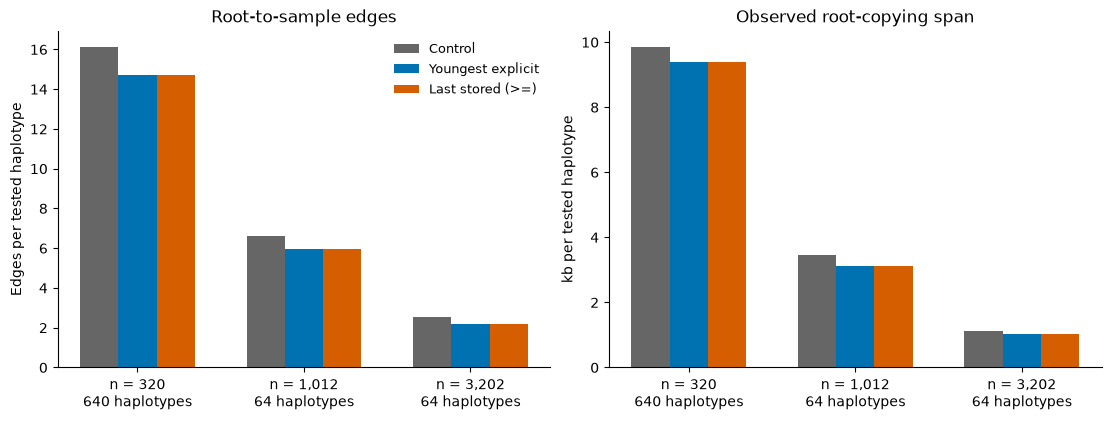

In [7]:
mode_order = settings["modes"]
mode_labels = {
    "control": "Control",
    "youngest": "Youngest explicit",
    "last_tie": "Last stored (>=)",
}
colors = {"control": "#666666", "youngest": "#0072B2", "last_tie": "#D55E00"}
nb_plot.plot_whole_region_results(
    artifact_dir=artifact_dir,
    colors=colors,
    mode_labels=mode_labels,
    mode_order=mode_order,
    whole=whole,
    whole_names=whole_names,
    figsize=(11, 4.1),
    width=0.23,
    ylim=(0, None),
    fontsize=9,
    dpi=180,
)

## Small real-data controls with pre-existing root edges

The 1–2 Mb control has 34 root edges; youngest selection leaves 32. The
10–11 Mb control has 30; youngest selection leaves 27. Root-copying span also
falls in both windows. These are full, unstitched HMM matches inside each
window, with an unchanged reference and unchanged likelihood compression.

,dataset,mode,haplotypes,root_edges,root_span_bp,root_edge_reduction_percentage,root_span_reduction_percentage
3,tgp_chr20p_n320_1_to_2mb,control,64,34,20364.0,0.000,0.000
4,tgp_chr20p_n320_1_to_2mb,youngest,64,32,19827.0,5.882,2.637
5,tgp_chr20p_n320_1_to_2mb,last_tie,64,32,19827.0,5.882,2.637
6,tgp_chr20p_n320_10_to_11mb,control,64,30,17367.0,0.000,0.000
7,tgp_chr20p_n320_10_to_11mb,youngest,64,27,16437.0,10.000,5.355
8,tgp_chr20p_n320_10_to_11mb,last_tie,64,27,16437.0,10.000,5.355


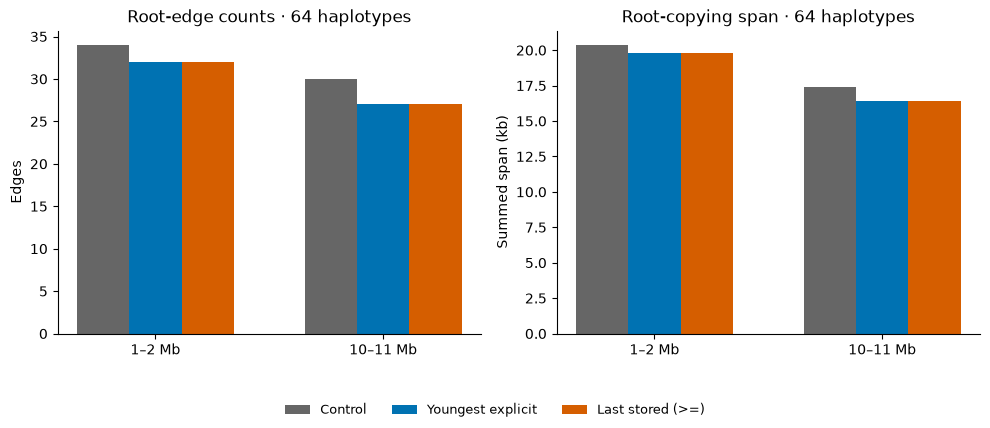

In [8]:
windows = summary.loc[summary.scope.eq("independent_1mb_window")].copy()
display.display(windows[columns].round(3))
window_names = windows.dataset.drop_duplicates().tolist()
nb_plot.plot_small_real_data_controls_with_pre_existing_root_edges(
    artifact_dir=artifact_dir,
    colors=colors,
    mode_labels=mode_labels,
    mode_order=mode_order,
    window_names=window_names,
    windows=windows,
    figsize=(10, 4.3),
    width=0.23,
    ylim=(0, None),
    fontsize=9,
    dpi=180,
)

## Tiny examples: when the comparison can and cannot help

All examples have four nodes and the required stem edge 0 → 1.
The first two have root-to-sample copying in the unmodified control.

1. **An explicit young alternative is tied with the root.** Node 1 has time 9;
   sibling nodes 2 and 3 have times 5 and 1. Three sites at 10, 20, 30 have
   mutations on nodes 3, 2, 2, and the query is `[0, 1, 0]`. The control path
   copies node 2 over `[0,30)` and root 1 over `[30,40)`. Both alternatives
   replace that final root segment with node 3. Root edges go **1 → 0**,
   with no mismatch or likelihood penalty.
2. **All younger alternatives are compressed.** The chain 0 → 1 → 2 → 3 has
   no mutations, and the one-site query is `[0]`. Only the root's likelihood
   is explicit. All three builds copy node 1: root edges stay **1 → 1**.
3. **Identical derived ancestors in a chain.** With mutations on node 2 at
   every site and query `[1,1,1]`, node 3 is implicitly represented by node 2.
   Both comparisons continue to select node 2.
4. **Last stored is not youngest.** Sibling nodes 2 and 3 have times 1 and 5,
   genotypes `[1,0]` and `[0,1]`, and query `[1,1]`. With recombination 0 and
   mismatch 1/8 the two single-parent paths are equally likely. Youngest
   keeps node 2; `>=` selects older node 3. This fourth case is a comparator
   diagnostic, not a proposed matching parameter setting.

In [9]:
display.display(
    toys[["example", "mode", "root_edges", "root_span_bp", "mismatches", "path"]]
)

,example,mode,root_edges,root_span_bp,mismatches,path
0,root_tie_explicit_young_alternative,control,1,10.0,0,"[[0, 30, 2], [30, 40, 1]]"
1,root_tie_young_alternative_compressed,control,1,20.0,0,"[[0, 20, 1]]"
2,derived_identical_chain,control,0,0.0,0,"[[0, 40, 2]]"
3,age_vs_last_stored_tie,control,0,0.0,1,"[[0, 30, 2]]"
4,root_tie_explicit_young_alternative,youngest,0,0.0,0,"[[0, 30, 2], [30, 40, 3]]"
5,root_tie_young_alternative_compressed,youngest,1,20.0,0,"[[0, 20, 1]]"
6,derived_identical_chain,youngest,0,0.0,0,"[[0, 40, 2]]"
7,age_vs_last_stored_tie,youngest,0,0.0,1,"[[0, 30, 2]]"
8,root_tie_explicit_young_alternative,last_tie,0,0.0,0,"[[0, 30, 2], [30, 40, 3]]"
9,root_tie_young_alternative_compressed,last_tie,1,20.0,0,"[[0, 20, 1]]"


## Likelihood and copying checks

For each returned path, calculate its log score from the same constant-rate
model: a stay contributes `log(1 - rho + rho / N)`, a switch contributes
`log(rho / N)`, and an emission contributes `log(1 - mu)` or `log(mu)`.
`N` is the unchanged total reference-node count, matching the C code. The
first site's common transition factor is included in every path's score.
Checks use the merged output segments and native copied alleles.

Across all 896 paired real-data requests, score differences are zero, all
mismatches remain zero, and no literal node-0 sample edges appear. No tested
haplotype gains a root edge or root-copying span under youngest selection.

In the complete n=320 run, youngest selection changes parents at 4,758,264
site/haplotype pairs, always toward a younger parent. The literal `>=` arm
changes 13,202,041 pairs, including **2,337,936 toward older parents**. Thus
its identical root-edge improvement should not be interpreted as generally
preferring recent ancestors.

In [10]:
assert summary.log_likelihood_max_abs_difference.max() == 0
assert summary.mutations.sum() == 0
assert summary.node0_edges.sum() == 0
assert summary.loc[summary["mode"].eq("control"), "root_edges"].gt(0).all()
youngest = paired.loc[paired["mode"].eq("youngest")]
assert youngest.root_edge_change.le(0).all()
assert youngest.root_span_change_bp.le(0).all()
age_checks = summary[
    [
        "dataset",
        "mode",
        "changed_parent_sites",
        "changed_to_younger_sites",
        "changed_to_older_sites",
        "root_sites_removed",
        "root_sites_added",
        "log_likelihood_max_abs_difference",
    ]
]
display.display(age_checks)
print("All paired real-data likelihood, mismatch and root-edge checks passed.")

,dataset,mode,changed_parent_sites,changed_to_younger_sites,changed_to_older_sites,root_sites_removed,root_sites_added,log_likelihood_max_abs_difference
0,tgp_chr20p_n320,control,0,0,0,0,0,0.0
1,tgp_chr20p_n320,youngest,4758264,4758264,0,3329,0,0.0
2,tgp_chr20p_n320,last_tie,13202041,4546082,2337936,3329,0,0.0
3,tgp_chr20p_n320_1_to_2mb,control,0,0,0,0,0,0.0
4,tgp_chr20p_n320_1_to_2mb,youngest,20829,20829,0,3,0,0.0
5,tgp_chr20p_n320_1_to_2mb,last_tie,58268,19323,14846,3,0,0.0
6,tgp_chr20p_n320_10_to_11mb,control,0,0,0,0,0,0.0
7,tgp_chr20p_n320_10_to_11mb,youngest,16812,16812,0,5,0,0.0
8,tgp_chr20p_n320_10_to_11mb,last_tie,43487,16681,7357,5,0,0.0
9,tgp_chr20p_n1012,control,0,0,0,0,0,0.0


All paired real-data likelihood, mismatch and root-edge checks passed.


## Interpretation and limits

The easy comparison change is useful: it removes roughly **9–13% of direct
root edges** in the whole-region tests, with an unchanged HMM score. It does
not eliminate the problem. The unchanged one-site example explains one
limitation directly: a comparison cannot recover a young alternative absent
from the explicit state list. These experiments do not determine how much of
the remaining root copying is due to compression versus a uniquely optimal
root-containing path.

The age-aware comparison is preferable to treating `>=` as an age policy:
both improve the root metric here, but only the former checks real ages.
This remains a preference among **explicitly represented** tied maxima, not
a guarantee of the youngest possible ancestor among all implicit states.

No ancestral reference was rebuilt, no stitched matching run was changed,
and no dating was performed. A reduction in these artificial root edges is
the measured outcome; improved genealogical or mutation-age accuracy has not
been established by this experiment.

## Reproduction and saved evidence

`data/ch5/tie_breaking/` contains the configuration, source snapshots, complete
experimental diffs, input checksums, per-haplotype metrics, paired metrics and
compressed copying paths. Original archived inputs are read only. All C builds
and reconstructed genotype arrays live in temporary directories. There are no
permanent source or extension changes in tsinfer.

The source snapshots reproduce the experiment with the existing tsinfer and
tsinfer-match-eval environments; `uv run` is used for Python tooling. The
following opt-in cell runs all three builds and writes a fresh set of results.
It needs a C compiler, the recorded local input archives, and the checkout at
the recorded revision. Ordinary notebook execution only reads saved results
and regenerates the two figures.

In [11]:
run_experiments = False
if run_experiments:
    command = [
        "uv",
        "run",
        "--no-project",
        "--python",
        settings["matching_python"],
        "python",
        str(artifact_dir / "source/reproduce.py"),
        "--config",
        str(artifact_dir / "experiment_config.json"),
        "--output",
        str(artifact_dir / "reproduced"),
    ]
    subprocess.run(command, check=True)

In [12]:
display.display(
    pd.Series(
        {
            "date": settings["date"],
            "tsinfer_commit": provenance["tsinfer_commit"],
            "recombination": settings["recombination"],
            "mismatch": settings["mismatch"],
            "matching_workers": settings["workers"],
            "real_data_requests_per_arm": len(paired.loc[paired["mode"].eq("control")]),
            "original_source_matches_control_copy": provenance[
                "source_control_matches_checkout"
            ],
            "likelihood_compression_unchanged": provenance[
                "compressed_likelihood_function_unchanged"
            ],
        }
    )
)

date                                                                  2026-10-22
tsinfer_commit                          6beae28f54acd6e657062b32a294c889496066c5
recombination                                                               0.01
mismatch                                                                     0.0
matching_workers                                                              18
real_data_requests_per_arm                                                   896
original_source_matches_control_copy                                        True
likelihood_compression_unchanged                                            True
dtype: object